# Parametric CZ Simulation

**NOTE**: All physical quantities are in GHz with $\hbar = 1$, unless otherwise specified or clearly unitless.

In [ ]:
using ProjectRoot
using Pkg
const ROOT = @projectroot 
Pkg.activate(ROOT)

using Revise
using QuantumToolbox
using XoniumUnitCell
using ProgressMeter
using CairoMakie

  Activating project at `~/Projects/xonium/XoniumUnitCell.jl`


In [ ]:
using LinearAlgebra

# run_spectography_flux_sweep_2a/run_cz_flux_sweep_2b parallelize their grid sweeps across Julia
# threads (see those functions' docstrings). Pin BLAS to 1 thread so the
# linear algebra inside each sesolve call doesn't spawn its own threads and
# oversubscribe the cores Julia's own threads are already using.
LinearAlgebra.BLAS.set_num_threads(1)

println("Threads.nthreads() = ", Threads.nthreads())
Threads.nthreads() == 1 && @warn "Only 1 thread available -- the sweep parallelism below will have no effect. Restart the kernel with more threads (VS Code: set \"julia.NumThreads\" to \"auto\" in settings, or set the JULIA_NUM_THREADS env var) before re-running."

Threads.nthreads() = 14

false

## Reproduction of (Ma. et. al 2024)

Import System Parameters

In [ ]:

const fA_params = (
    EC = 1.61 * 2π,
    EL = 0.45 * 2π,
    EJ = 2.89 * 2π,
    δϕ = π, # sweet spot (Φ=Φ0/2), matching fluxonium()'s own default and the paper's operating point
    name = :fA
)

const fB_params = (
    EC = 1.24 * 2π,
    EL = 0.45 * 2π,
    EJ = 2.68 * 2π,
    δϕ = π,
    name = :fB
)
const J = -3.5* 2π * 1e-3 # magnitude factor to convert from MHz to GHz

-0.02199114857512855

### Sweep couplings over flux bias

In [ ]:
# true detuning of both fluxonia from the sweet spot Φ0/2, as a flux angle 2πδΦ/Φ0 (total bias π + δϕ)
δϕs = collect(LinRange(-0.5, 0.5, 100)) * 2π
0.0 ∈ δϕs || (δϕs = sort!([δϕs; 0.0]))  # always include the sweet spot

# XoniumUnitCell implements H = ... − J(φA + ϕA)(φB + ϕB), so the coupling magnitude is passed;
# the notebook's J carries the sign of the old +J convention
sweep = sweep_couplings(δϕs, fA_params, fB_params, XoniumUnitCell.build_H_S1, -J)

101-element StructArray(::Vector{ComplexF64}, ::Vector{ComplexF64}, ::Vector{ComplexF64}, ::Vector{ComplexF64}) with eltype @NamedTuple{xx::ComplexF64, xz::ComplexF64, zx::ComplexF64, zz::ComplexF64}:
 (xx = -0.02657257072685102 + 0.0im, xz = 0.0 + 0.0im, zx = 0.0 + 0.0im, zz = 0.0 + 0.0im)
 (xx = -0.026556811403104865 + 0.0im, xz = -0.0010507472232077967 + 0.0im, zx = -0.0017151132081933934 + 0.0im, zz = -6.786019652892241e-5 + 0.0im)
 (xx = -0.026509176095108025 + 0.0im, xz = -0.0021104878805253916 + 0.0im, zx = -0.003442016592379537 + 0.0im, zz = -0.0002740309346741587 + 0.0im)
 (xx = -0.0264286107326292 + 0.0im, xz = -0.003188202572689671 + 0.0im, zx = -0.005191788711487778 + 0.0im, zz = -0.0006263089003914441 + 0.0im)
 (xx = -0.026313420582427516 + 0.0im, xz = -0.004292829414983159 + 0.0im, zx = -0.006974036531705809 + 0.0im, zz = -0.0011377596869510417 + 0.0im)
 (xx = -0.026161370707799017 + 0.0im, xz = -0.005433199967192249 + 0.0im, zx = -0.008796051396874446 + 0.0im, zz = -0.00

### Plot couplings vs. flux bias

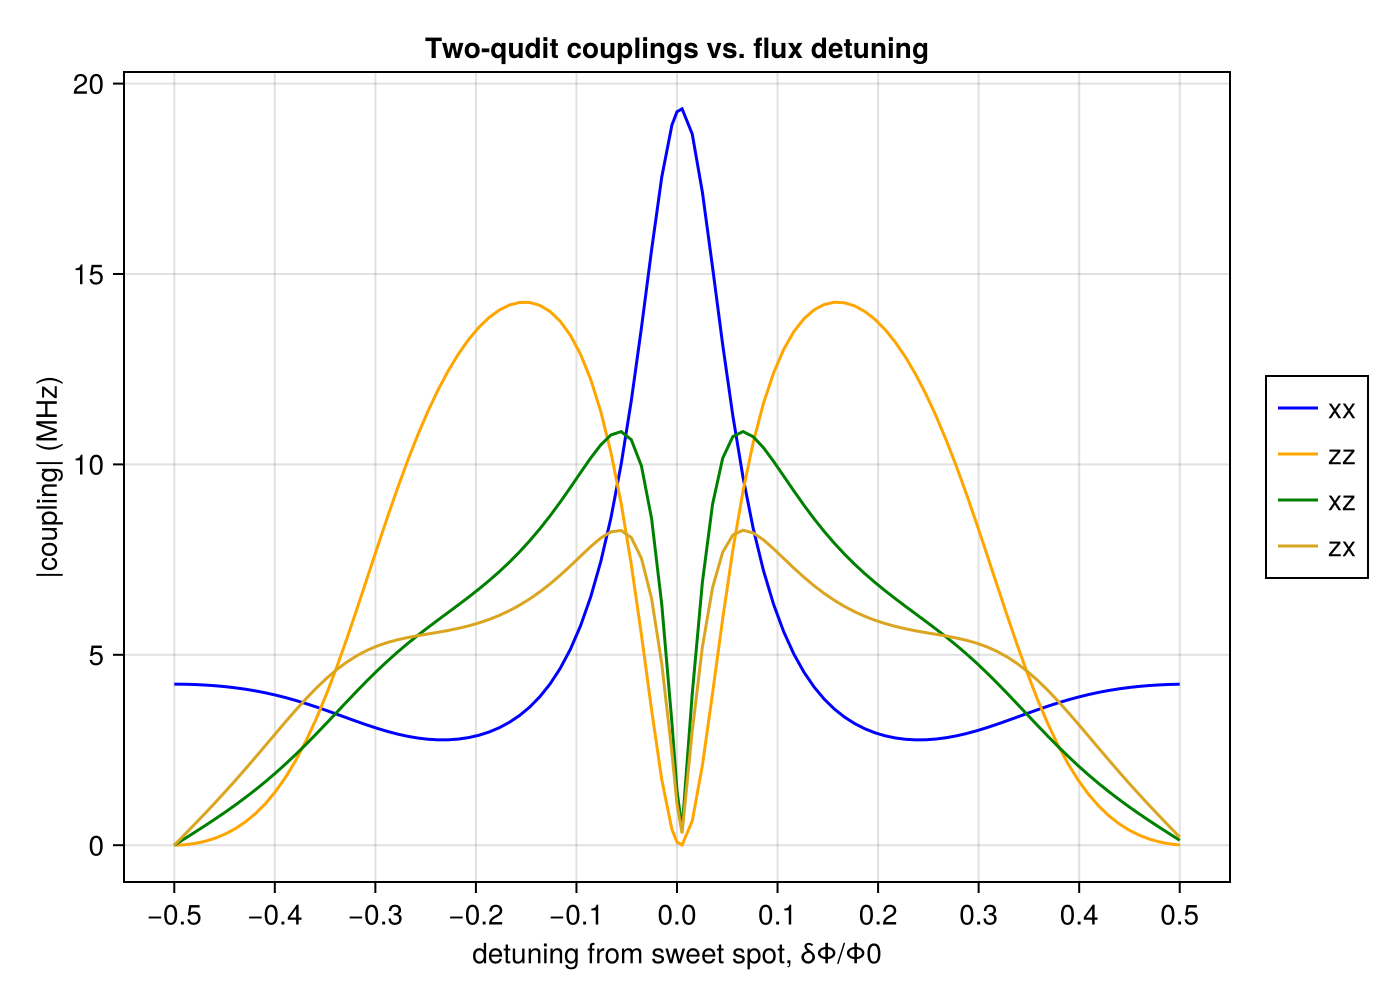

In [ ]:
# sign toggles (+1 or -1): multiply the plotted curves, e.g. to undo an arbitrary eigenvector-gauge flip
xx, xz, zx = 1, 1, 1
toggles = (xx = xx, zz = 1, xz = xz, zx = zx)

fig = Figure(size = (700, 500))

ax = Axis(
    fig[1, 1];
    xlabel = "detuning from sweet spot, δΦ/Φ0",
    ylabel = "|coupling| (MHz)",
    title = "Two-qudit couplings vs. flux detuning",
    xticks = -0.5:0.1:0.5,
    yticks = [-10, -5, 0, 5, 10, 15, 20],
    xgridvisible = true,
    ygridvisible = true,
)

component_colors = Dict(:xx => :blue, :zz => :orange, :xz => :green, :zx => :goldenrod)

foreach((:xx, :zz, :xz, :zx)) do component
    lines!(ax, δϕs./2π, toggles[component] .* 1e3 .*abs.(getproperty(sweep, component))./2π; label = String(component), color = component_colors[component])
end

Legend(fig[1, 2], ax)
fig

In [ ]:
# Fig. 2a: spectroscopy of qubit A while sweeping the flux detuning of qubit B and the probe frequency
ωlist_2a = 2π .* LinRange(1.0, 1.06, 50)
δϕB_list_2a = 2π .* LinRange(-0.1, 0.1, 50)  # detuning of qubit B from the sweet spot, as 2πδΦ_B/Φ0 (total bias π + δϕ)

# demo placeholders for the pulse/sweep parameters the sweep needs but
# this cell doesn't otherwise define -- tune to match the target figure
tlist = collect(LinRange(0, 100, 2))
t_ramp = 2.0
Ω_ge = 0.1

# drive envelope; the sweep multiplies it by cos(ωt) for every ω in ωlist_2a
env0 = cosine_ramp_envelope(t_ramp, maximum(tlist) - 2t_ramp)
env(p, t) = env0(t)

# run 2 a sweep over ranges, collect result. The sweep takes the coupling magnitude, the notebook's J has the opposite sign
P_transition = run_spectography_flux_sweep_2a(fA_params, fB_params, tlist, env, δϕB_list_2a, ωlist_2a, -J, Ω_ge)

# Fig. 2b/c: dynamical CZ experiment, τ = 200 ns, tanh ramps with t_r = 2 ns (paper settings)
δϕA_list_2b = 2π .* LinRange(-0.10, 0.02, 25)   # detuning from the sweet spot Φ0/2, as a flux angle 2πδΦ/Φ0
δϕB_list_2b = 2π .* LinRange(-0.10, 0.02, 25)

# run 2 b sweep over ranges, collect result. As for 2a, the sweep takes the coupling magnitude
vϕ_mtrx, err_mtrx, branch_mtrx, leak_mtrx = run_cz_flux_sweep_2b(fA_params, fB_params, δϕA_list_2b, δϕB_list_2b, -J; τ=200.0, t_ramp=12.0, ramp_profile=:tanh);


Spectroscopy sweep:   0%|                 |  ETA: 2:10:04 ( 3.12  s/it)


Spectroscopy sweep:   5%|▉                |  ETA: 0:02:23 (60.31 ms/it)


Spectroscopy sweep:   6%|█                |  ETA: 0:02:09 (54.56 ms/it)


Spectroscopy sweep:   6%|█▏               |  ETA: 0:01:58 (50.41 ms/it)


Spectroscopy sweep:   7%|█▏               |  ETA: 0:01:50 (47.21 ms/it)

...


CZ flux sweep:  99%|█████████████████████▊|  ETA: 0:00:01 ( 0.15  s/it)


CZ flux sweep:  99%|█████████████████████▊|  ETA: 0:00:01 ( 0.15  s/it)


CZ flux sweep:  99%|█████████████████████▉|  ETA: 0:00:01 ( 0.15  s/it)


CZ flux sweep:  99%|██████████████████████|  ETA: 0:00:00 ( 0.16  s/it)


CZ flux sweep: 100%|██████████████████████| Time: 0:01:38 ( 0.16  s/it)


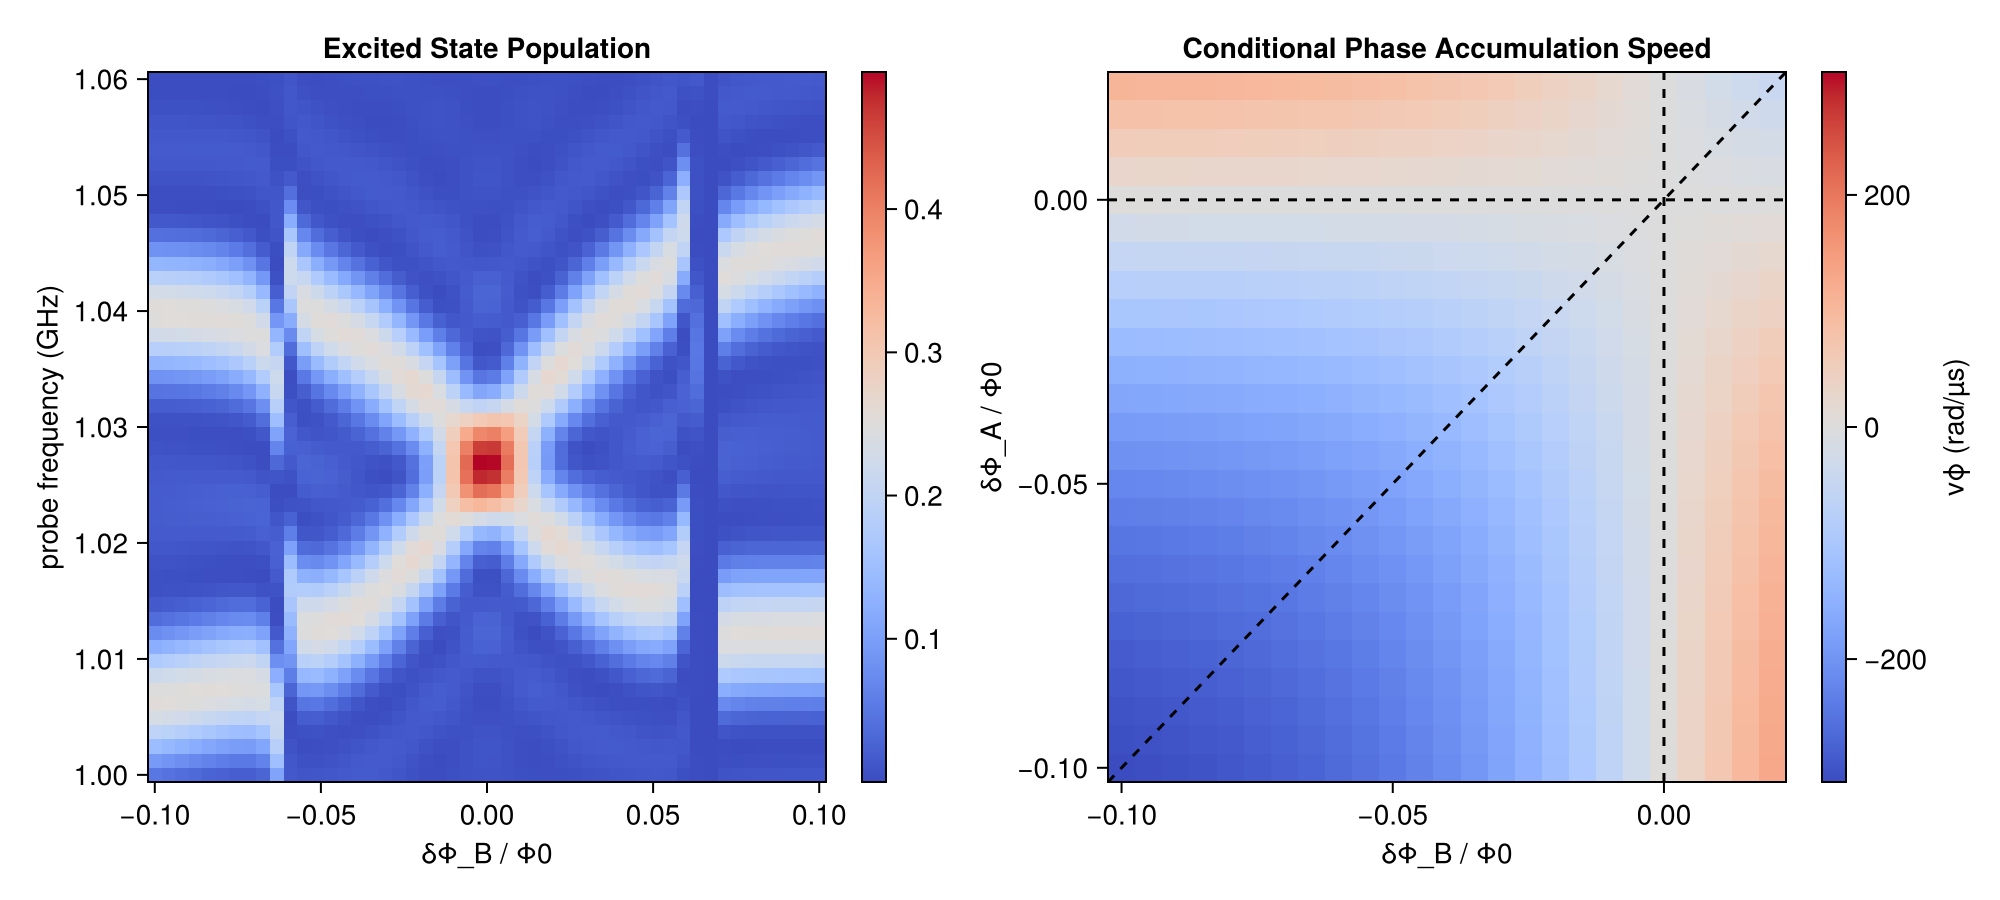

In [ ]:
# plot results from above in heatmaps, side by side
# both plots go from blue for low value to red for high value 

fig = Figure(size = (1000, 450))

# fig A y-axis, probe frequency in GHz
# fig A x-axis, ϕB detuning from sweet spot
ax_a = Axis(fig[1, 1];
    xlabel = "δΦ_B / Φ0",
    ylabel = "probe frequency (GHz)",
    title = "Excited State Population",
)
hm_a = heatmap!(ax_a, δϕB_list_2a ./ 2π, ωlist_2a ./ 2π, permutedims(P_transition); colormap = :coolwarm)
Colorbar(fig[1, 2], hm_a)

# fig C: conditional-phase accumulation speed, paper convention vϕ = 4 g_zz (blue < 0 < red)
ax_b = Axis(fig[1, 3];
    xlabel = "δΦ_B / Φ0",
    ylabel = "δΦ_A / Φ0",
    title = "Conditional Phase Accumulation Speed",
)
vmax = maximum(abs, vϕ_mtrx)
hm_b = heatmap!(ax_b, δϕB_list_2b ./ 2π, δϕA_list_2b ./ 2π, permutedims(vϕ_mtrx);
    colormap = :coolwarm, colorrange = (-vmax, vmax))
hlines!(ax_b, [0.0]; color = :black, linestyle = :dash)
vlines!(ax_b, [0.0]; color = :black, linestyle = :dash)
ablines!(ax_b, 0.0, 1.0; color = :black, linestyle = :dash)   # δΦA = δΦB
Colorbar(fig[1, 4], hm_b; label = "vϕ (rad/µs)")

fig

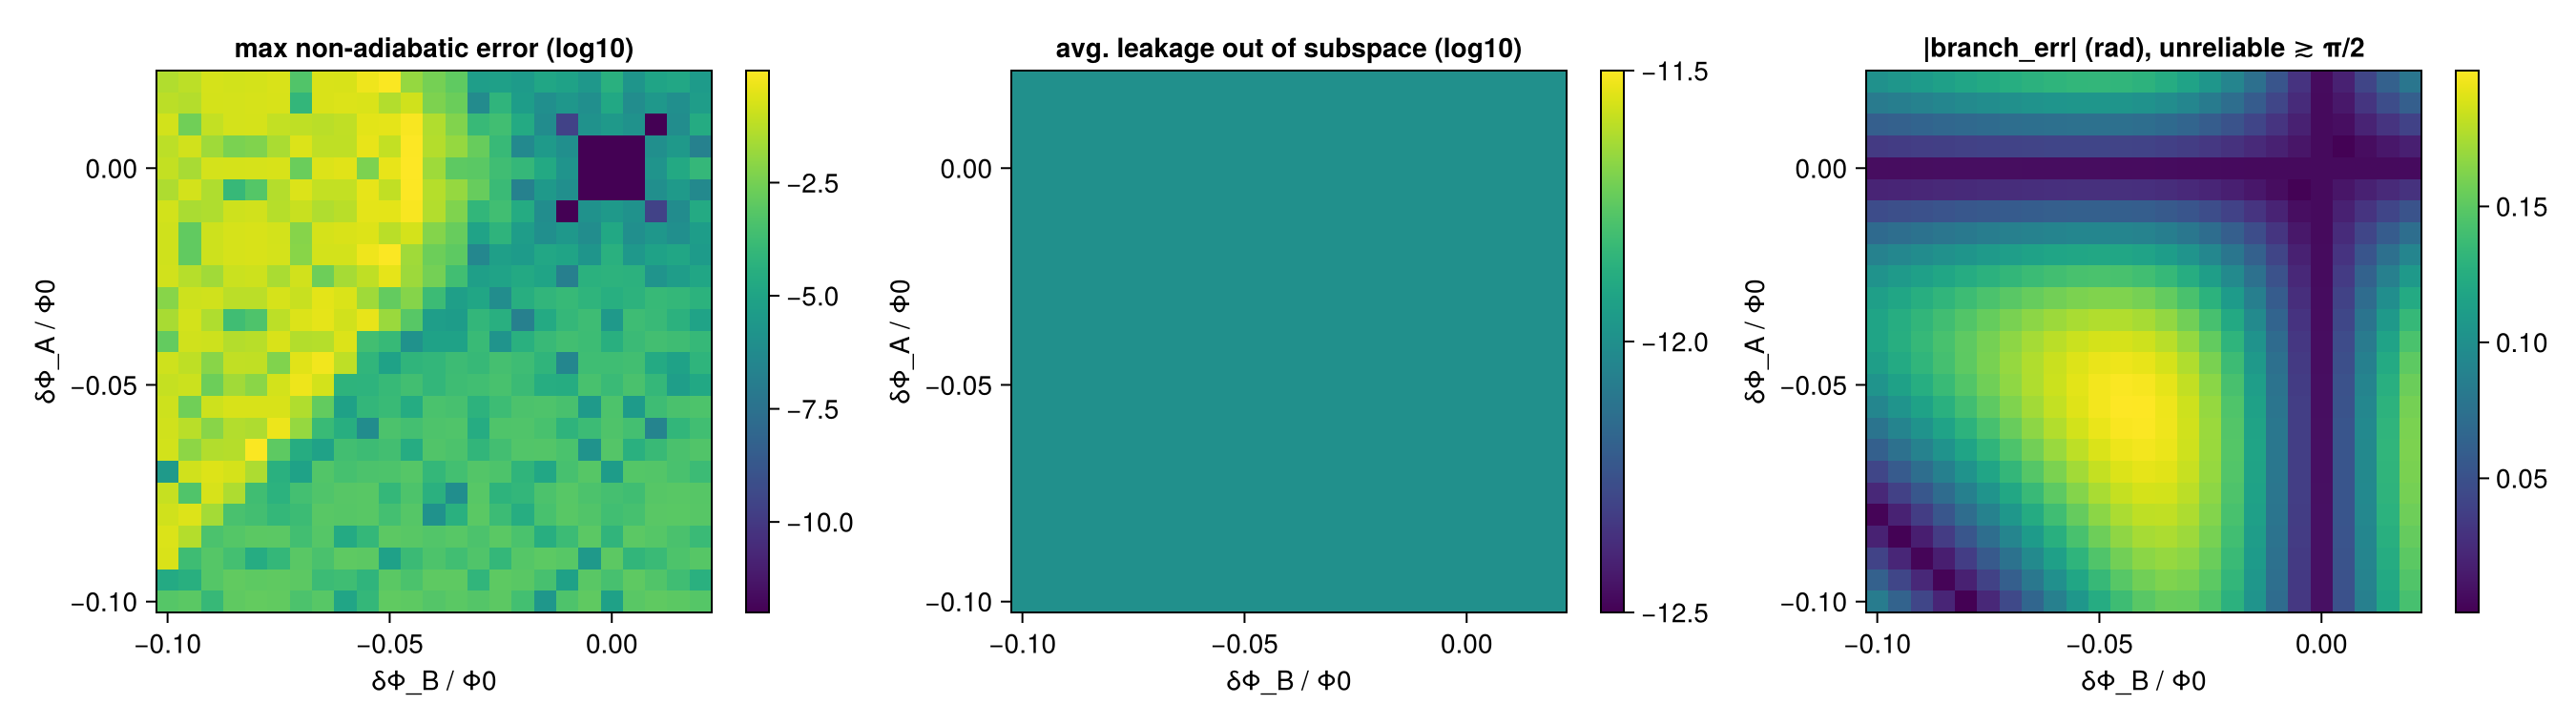

In [ ]:
# diagnostics for the Fig. 2c sweep: non-adiabatic error, leakage, and 2π-branch confidence
fig_diag = Figure(size = (1350, 380))
ax_e = Axis(fig_diag[1, 1]; xlabel = "δΦ_B / Φ0", ylabel = "δΦ_A / Φ0", title = "max non-adiabatic error (log10)")
hm_e = heatmap!(ax_e, δϕB_list_2b ./ 2π, δϕA_list_2b ./ 2π, permutedims(log10.(max.(err_mtrx, 1e-12))); colormap = :viridis)
Colorbar(fig_diag[1, 2], hm_e)
ax_l = Axis(fig_diag[1, 3]; xlabel = "δΦ_B / Φ0", ylabel = "δΦ_A / Φ0", title = "avg. leakage out of subspace (log10)")
hm_l = heatmap!(ax_l, δϕB_list_2b ./ 2π, δϕA_list_2b ./ 2π, permutedims(log10.(max.(leak_mtrx, 1e-12))); colormap = :viridis)
Colorbar(fig_diag[1, 4], hm_l)
ax_r = Axis(fig_diag[1, 5]; xlabel = "δΦ_B / Φ0", ylabel = "δΦ_A / Φ0", title = "|branch_err| (rad), unreliable ≳ π/2")
hm_r = heatmap!(ax_r, δϕB_list_2b ./ 2π, δϕA_list_2b ./ 2π, permutedims(abs.(branch_mtrx)); colormap = :viridis)
Colorbar(fig_diag[1, 6], hm_r)
fig_diag

In [ ]:
nθ = 400        # dense samples of the drive phase θ = ωt over one period (multiple of 4 and of nT_check)
nT_check = 20   # Floquet sample times for the consistency check
δλ_check = 0.5 # δλ for the tracked FloquetBasis of the consistency check

ωlist = 2π*1e-3 .* (50, 5, 0.5) # frequencies in Fig 3.b 
Φlist = LinRange(0.0, 0.1, 10)

# Instantaneous eigenstates: for drives far slower than the qubit frequencies the Floquet
# states follow the eigenstates of H(δ) = H_idle + δ ΦA_op, with ΦA_op = EL_A φA − J φB (exact up to a
# c-number, see `flux_drive_operators`), and δ(t) = 2πΦ cos(ωt) on qubit A and qubit B at Φ0/2. Both fluxonia
# are parked 5 mrad off the sweet spot. ⟨φA⟩ then depends on t only through θ = ωt, so the results are
# independent of ω. As for the other sweeps, the coupling magnitude -J is passed.
fig3 = run_flux_modulation_sweep(fA_params, fB_params, Φlist, -J; δϕ_offsets=(0.005, -0.005), nθ=nθ,
                                 H_builder_kwargs=(qho_basis_nlev=40,))
φt_sweep = fig3.φt_sweep   # ⟨φA⟩(θ) of (gg, ge, eg, ee) at each Φ
# same value for every drive frequency in the adiabatic limit
∂ωs = ones(length(ωlist)) * fig3.∂0'
∂λ_1 = ones(length(ωlist)) * fig3.∂1' # first-harmonic amplitude, same combination as ∂ωs

# Consistency check against tracked Floquet states at the largest drive amplitude and the
# fastest drive, where non-adiabatic corrections are largest.
chk = floquet_instantaneous_check(fig3.sys, -J, maximum(ωlist), maximum(Φlist); nθ=nθ, nT=nT_check, δλ=δλ_check)
println("Consistency check at ω/2π = $(round(1e3 * maximum(ωlist) / 2π, sigdigits=3)) MHz, Φ = $(maximum(Φlist)) Φ0, δλ = $δλ_check:")
for lbl in keys(chk.min_overlap)
    println("  $lbl: min |⟨inst|Floquet⟩|² = $(round(chk.min_overlap[lbl], digits=5)), ",
            "max |Δ⟨φA⟩| = $(round(chk.max_Δφ[lbl], sigdigits=3))")
end
println("  ∂ωs:  Floquet $(round(chk.Floquet.∂0, sigdigits=4)), instantaneous $(round(chk.instantaneous.∂0, sigdigits=4))")
println("  ∂λ_1: Floquet $(round(chk.Floquet.∂1, sigdigits=4)), instantaneous $(round(chk.instantaneous.∂1, sigdigits=4))",
        " (both from the $nT_check check samples)")


Flux modulation sweep:  20%|██▊           |  ETA: 0:00:03 ( 0.40  s/it)


Flux modulation sweep: 100%|██████████████| Time: 0:00:00 (81.47 ms/it)


Consistency check at ω/2π = 50.0 MHz, Φ = 0.1 Φ0, δλ = 0.5:


  gg: min |⟨inst|Floquet⟩|² = 0.99794, max |Δ⟨φA⟩| = 0.0124
  ge: min |⟨inst|Floquet⟩|² = 0.99404, max |Δ⟨φA⟩| = 0.0252
  eg: min |⟨inst|Floquet⟩|² = 0.99404, max |Δ⟨φA⟩| = 0.0253
  ee: min |⟨inst|Floquet⟩|² = 0.99792, max |Δ⟨φA⟩| = 0.0124
  ∂ωs:  Floquet 0.02689, instantaneous 0.02339
  ∂λ_1: Floquet 4.2, instantaneous 4.206 (both from the 20 check samples)


In [ ]:
# Estimated dephasing rate Γφ from the environmental noise PSD (src/env_psd.jl).
# The weights gₖ are the harmonics of ½(⟨φA⟩_e − ⟨φA⟩_g) along the instantaneous eigenstates, for the
# qubit-A transition with B in |g⟩ (gg→eg) and in |e⟩ (ge→ee); the two rates are averaged, as in `differentials`.
# gₖ depend on the drive only through θ = ωt, so ω enters Γφ only through S(kω).
S_noise = qubit_pink_noise(fA_params; qho_basis_nlev=40, kT=thermal_energy(80e-3))  # noise model of qubit A, at 80 mK (= 2π·1.38·8/6.63)

Γφ = dephasing_rates(φt_sweep, ωlist, S_noise)   # rate in 1/ns, indexed [ω, Φ]

3×10 Matrix{Float64}:
 2.59036e-6  2.57714e-6  2.53917e-6  …  2.32147e-6  2.30904e-6  2.30485e-6
 2.59036e-6  2.54807e-6  2.429e-6       1.55013e-6  1.41983e-6  1.30845e-6
 2.59036e-6  2.56287e-6  2.48507e-6     1.92932e-6  1.85076e-6  1.78369e-6

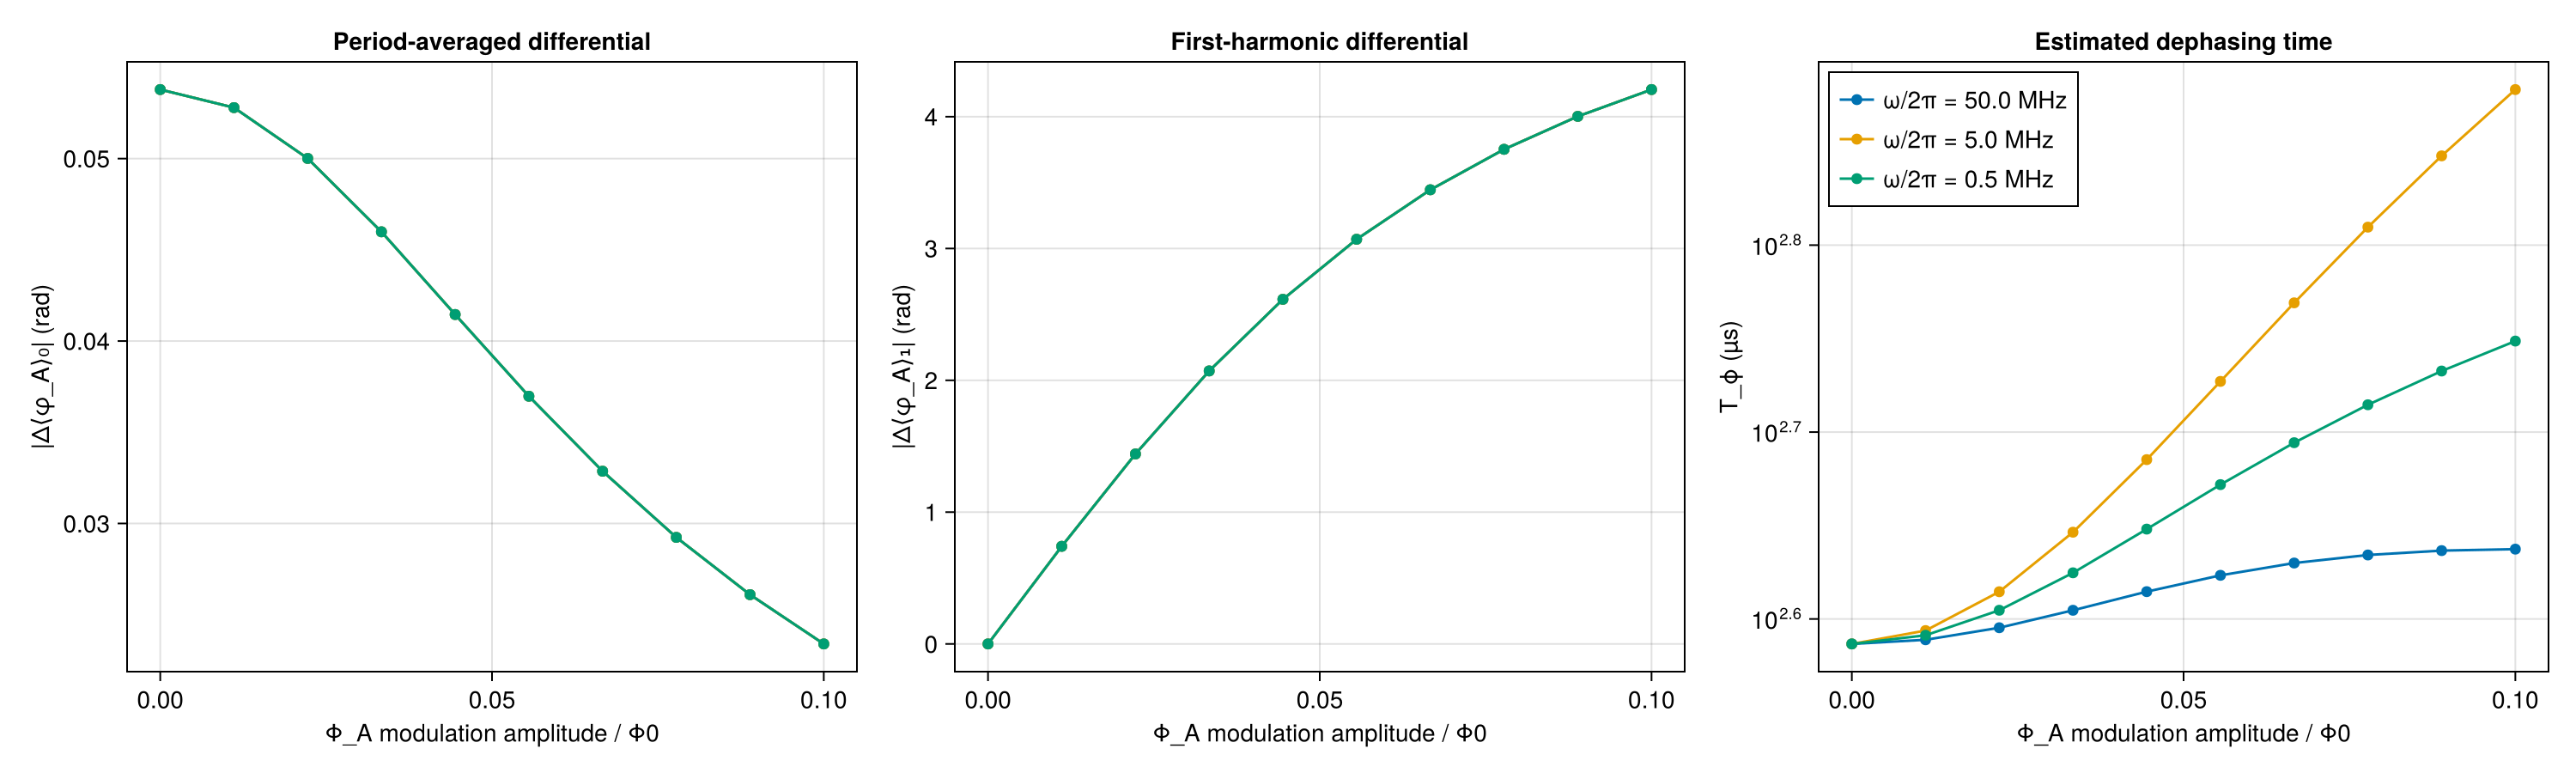

In [ ]:
# plot the period-averaged (∂ωs) and first-harmonic (∂λ_1) differentials side by side,
# one curve per drive frequency
fig_dd = Figure(size = (1500, 450))

ax_0 = Axis(fig_dd[1, 1];
    xlabel = "Φ_A modulation amplitude / Φ0",
    ylabel = "|Δ⟨φ_A⟩₀| (rad)",
    title = "Period-averaged differential",
)
ax_1 = Axis(fig_dd[1, 2];
    xlabel = "Φ_A modulation amplitude / Φ0",
    ylabel = "|Δ⟨φ_A⟩₁| (rad)",
    title = "First-harmonic differential",
)
ax_2 = Axis(fig_dd[1, 3];
    xlabel = "Φ_A modulation amplitude / Φ0",
    ylabel = "T_ϕ (µs)",
    title = "Estimated dephasing time",
    yscale = log10,
)
for (i, ω) in enumerate(ωlist)
    lbl = "ω/2π = $(round(1e3 * ω / 2π, sigdigits=3)) MHz"
    scatterlines!(ax_0, Φlist, ∂ωs[i, :]; label = lbl)
    scatterlines!(ax_1, Φlist, ∂λ_1[i, :]; label = lbl)
    scatterlines!(ax_2, Φlist, 1e-3 .* (Γφ[i, :].^-1); label = lbl)   # 1/ns → 1/µs
end
axislegend(ax_2; position = :lt)

fig_dd